# Numerical Methods for Finance - MMF2021

# Project 2 – Credit Risk

# Author: Jaime Corzo Galdó

This project studies the credit risk of a portfolio of BBB-rated bonds issued by different counterparties.

We compare two approaches:

- **Method A:** Multivariate Gaussian distribution.
- **Method B:** Gaussian copula with discrete rating transitions.

Both models use a correlation parameter of 0.5.

We simulate 1,000,000 future portfolio values to estimate the expected credit loss and the 99th percentile of the loss distribution. We then extend the analysis to portfolios of 10 and 100 bonds.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

N = 1_000_000
rho = 0.5

rng = np.random.default_rng(42) # random generator for reproducibility

In [2]:
ratings = ["AAA", "AA", "A", "BBB", "BB", "B", "CCC", "Default"]

probabilities = np.array([
    0.02, 0.33, 5.95, 86.93,
    5.30, 1.17, 0.12, 0.18
]) / 100

bond_values = np.array([
    109.37, 109.19, 108.66, 107.55,
    102.02, 98.10, 83.64, 51.13
])

bond_table = pd.DataFrame({
    "Rating": ratings,
    "Probability (%)": probabilities * 100,
    "Future Value ($)": bond_values
})

assert np.isclose(probabilities.sum(), 1.0)

bond_table

,Rating,Probability (%),Future Value ($)
0,AAA,0.02,109.37
1,AA,0.33,109.19
2,A,5.95,108.66
3,BBB,86.93,107.55
4,BB,5.30,102.02
5,B,1.17,98.10
6,CCC,0.12,83.64
7,Default,0.18,51.13


## Bond Value Distribution

The bonds initially have a BBB rating. The transition probabilities describe the possible credit ratings after one year, while the corresponding bond values reflect the impact of credit migration or default.

We first calculate the expected future value and standard deviation of an individual bond. These will be used to construct the Gaussian approximation in Method A.

In [3]:
mean_value = np.sum(probabilities * bond_values)

variance = np.sum(
    probabilities * (bond_values - mean_value)**2
)

std_value = np.sqrt(variance)

print(f"Expected future bond value: ${mean_value:.4f}")
print(f"Variance: {variance:.4f}")
print(f"Standard deviation: ${std_value:.4f}")

Expected future bond value: $107.0879
Variance: 8.9508
Standard deviation: $2.9918


## Method A – Multivariate Gaussian Distribution

We approximate the future value of each BBB bond using a normal distribution, with the mean and standard deviation calculated from the rating transition table.

We simulate two bond values jointly, assuming a correlation of 0.5 between them.

The portfolio contains one bond from each issuer, so its future value is the sum of the two simulated bond values.

In [4]:
# Covariance matrix
cov_matrix = np.array([
    [variance, rho * variance],
    [rho * variance, variance]
])

# Simulate correlated future bond values
future_bonds_A = rng.multivariate_normal(
    mean=[mean_value, mean_value],
    cov=cov_matrix,
    size=N
)

# Future portfolio value (one of each bond)
future_portfolio_A = future_bonds_A.sum(axis=1)

print(future_bonds_A[:5])

[[107.85411181 104.74270417]
 [103.73654521 106.55051152]
 [114.0908935  110.1950539 ]
 [107.22975326 106.28362379]
 [108.40751066 105.85538762]]


In [5]:
# Portfolio reference value
V0 = 2 * mean_value

# Simulated losses
losses_A = V0 - future_portfolio_A

# Risk measures
mean_loss_A = np.mean(losses_A)
downside_loss_A = np.mean(np.maximum(losses_A, 0))
var99_A = np.percentile(losses_A, 99)

print(f"Portfolio reference value: ${V0:.4f}")
print(f"Mean net loss: ${mean_loss_A:.4f}")
print(f"Expected positive loss: ${downside_loss_A:.4f}")
print(f"99% Credit VaR: ${var99_A:.4f}")

Portfolio reference value: $214.1758
Mean net loss: $0.0007
Expected positive loss: $2.0648
99% Credit VaR: $12.0544


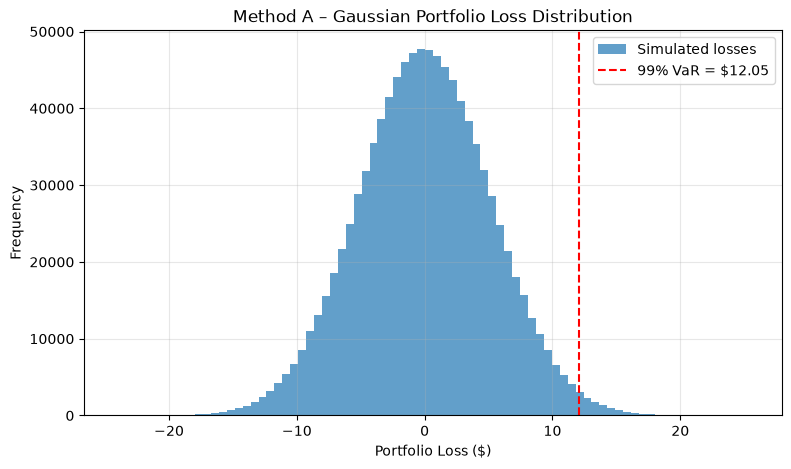

In [6]:
plt.figure(figsize=(9, 5))

plt.hist(losses_A, bins=80, alpha=0.7,
         label="Simulated losses")

plt.axvline(var99_A, color="red", linestyle="--",
            label=f"99% VaR = ${var99_A:.2f}")

plt.xlabel("Portfolio Loss ($)")
plt.ylabel("Frequency")
plt.title("Method A – Gaussian Portfolio Loss Distribution")

plt.grid(alpha=0.3)
plt.legend()
plt.show()

### Results – Method A

The multivariate Gaussian model produces a symmetric distribution of portfolio gains and losses.

The mean net loss is close to zero because the reference portfolio value is defined as the expected future value of the two bonds.

The 99% Credit VaR is approximately $12.05, meaning that losses exceed this amount in about 1% of the simulated scenarios.

A limitation of this approach is that the normal distribution does not capture the discrete rating transitions or the large loss associated with default. We will examine this difference using the Gaussian copula model.

## Method B – Gaussian Copula

In this approach, we keep the discrete rating transition probabilities and bond values from the original table.

We use a Gaussian copula with a correlation parameter of 0.5 to generate dependent outcomes for the two bonds.

The simulated uniform variables are mapped to future credit ratings using the cumulative transition probabilities.

In [7]:
# Order ratings from worst to best
ratings_B = ratings[::-1]
prob_B = probabilities[::-1]
values_B = bond_values[::-1]

# Cumulative transition probabilities
cum_prob = np.cumsum(prob_B)

# Normal thresholds
z_thresholds = norm.ppf(cum_prob[:-1])

threshold_table = pd.DataFrame({
    "Rating": ratings_B,
    "Probability": prob_B,
    "Cumulative Probability": cum_prob,
    "Z Threshold": np.append(z_thresholds, np.inf)
})

threshold_table

,Rating,Probability,Cumulative Probability,Z Threshold
0,Default,0.0018,0.0018,-2.911238
1,CCC,0.0012,0.0030,-2.747781
2,B,0.0117,0.0147,-2.178081
3,BB,0.0530,0.0677,-1.493142
4,BBB,0.8693,0.9370,1.530068
5,A,0.0595,0.9965,2.696844
6,AA,0.0033,0.9998,3.540084
7,AAA,0.0002,1.0000,inf


In [8]:
# Gaussian copula correlation matrix
corr_matrix = np.array([
    [1, rho],
    [rho, 1]
])

# Generate correlated standard normal variables
Z_B = rng.multivariate_normal(
    mean=[0, 0],
    cov=corr_matrix,
    size=N
)

# Transform normals into uniforms
U_B = norm.cdf(Z_B)

# Map uniforms to rating categories
# For exampe if we obtain U=0.0025, it will be between the cumulative probability 0.0018 and 0.0030,
# which means that the rating will be CCC and the bond will have a value of $83.64.
rating_indices_B = np.searchsorted(cum_prob, U_B)

# Assign future bond values
future_bonds_B = values_B[rating_indices_B]

# Future portfolio value
future_portfolio_B = future_bonds_B.sum(axis=1)

print(future_bonds_B[:5])

[[107.55 107.55]
 [107.55 107.55]
 [107.55 107.55]
 [107.55 107.55]
 [107.55 107.55]]


In [9]:
# Default corresponds to index 0 in our reordered table
default_bond1 = rating_indices_B[:, 0] == 0
default_bond2 = rating_indices_B[:, 1] == 0

pd1 = default_bond1.mean()
pd2 = default_bond2.mean()
joint_pd = (default_bond1 & default_bond2).mean()

print(f"Bond 1 default probability: {pd1:.4%}")
print(f"Bond 2 default probability: {pd2:.4%}")
print(f"Joint default probability: {joint_pd:.4%}")
print(f"Correlation of latent normals: {np.corrcoef(Z_B.T)[0, 1]:.4f}")

Bond 1 default probability: 0.1755%
Bond 2 default probability: 0.1759%
Joint default probability: 0.0121%
Correlation of latent normals: 0.5000


### Checking the Simulated Default Probabilities

We check whether the simulation reproduces the default probabilities from the original transition table.

Since we reordered the ratings from worst to best, Default corresponds to index 0. The expressions `rating_indices_B[:, 0] == 0` and `rating_indices_B[:, 1] == 0` identify which simulations result in default for each bond.

These comparisons return Boolean arrays (True for default, False otherwise). Taking their mean gives the proportion of simulations in which each bond defaults, since Python treats True as 1 and False as 0.

The expression `default_bond1 & default_bond2` identifies scenarios where both bonds default simultaneously. Its mean gives the joint default probability.

Finally, we calculate the correlation between the simulated normal variables to check that it is close to our assumed value of 0.5.

The individual default probabilities should be close to the original 0.18%. This works because the Gaussian copula generates uniform marginal distributions, and we assign ratings using the cumulative probabilities from the original table. The correlation changes how often the two bonds experience adverse outcomes together, without changing their individual probabilities.

In [10]:
# Simulated portfolio losses
losses_B = V0 - future_portfolio_B

# Risk measures
mean_loss_B = np.mean(losses_B)
downside_loss_B = np.mean(np.maximum(losses_B, 0))
var99_B = np.percentile(losses_B, 99)

print(f"Portfolio reference value: ${V0:.4f}")
print(f"Mean net loss: ${mean_loss_B:.4f}")
print(f"Expected positive loss: ${downside_loss_B:.4f}")
print(f"99% Credit VaR: ${var99_B:.4f}")

Portfolio reference value: $214.1758
Mean net loss: $-0.0043
Expected positive loss: $0.9549
99% Credit VaR: $14.0558


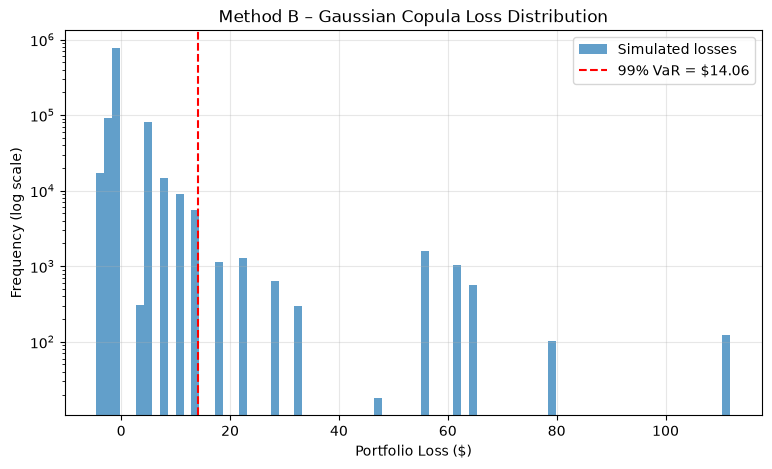

In [11]:
plt.figure(figsize=(9, 5))

plt.hist(losses_B, bins=80, alpha=0.7,
         label="Simulated losses")

plt.axvline(var99_B, color="red", linestyle="--",
            label=f"99% VaR = ${var99_B:.2f}")

plt.xlabel("Portfolio Loss ($)")
plt.ylabel("Frequency (log scale)")
plt.title("Method B – Gaussian Copula Loss Distribution")

plt.yscale("log")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### Understanding the Loss Distribution

The histogram shows how frequently different portfolio losses occur across the 1,000,000 Monte Carlo simulations.

Each simulation produces a future rating for both bonds. Using the bond values associated with those ratings, we calculate the portfolio loss as the difference between the reference value and the simulated future value.

Most simulations produce small gains or losses because the BBB rating has a very high probability (86.93%). Larger losses occur when one or both bonds are downgraded, particularly when a bond defaults.

The histogram therefore represents the full distribution of credit migration and default losses, not just the number of defaults.

The horizontal axis shows the portfolio loss in dollars, while the vertical axis shows how frequently each loss occurs. We use a logarithmic scale to make the less frequent extreme losses easier to see.

The red dashed line represents the 99% Credit VaR. Approximately 99% of simulated losses are at or below this value, while the remaining 1% are greater.

### Results – Method B

The Gaussian copula preserves the discrete rating transitions and bond values while introducing dependence between the two issuers.

The simulated default probabilities are close to the probabilities provided in the transition table.

The 99% Credit VaR is approximately $14.06, compared with $12.05 under the multivariate Gaussian approximation.

The higher VaR reflects the asymmetric distribution of bond values, particularly the large loss associated with default, which is not fully captured by the normal approximation.

## Comparison of the Two Methods

We compare the expected losses and the 99% Credit VaR obtained from the multivariate Gaussian model and the Gaussian copula model.

Both approaches use the same marginal mean, variance, portfolio reference value, and correlation parameter. The main difference is how they represent the distribution of future bond values.

In [12]:
comparison = pd.DataFrame({
    "Method": ["Multivariate Gaussian", "Gaussian Copula"],
    "Mean Net Loss ($)": [mean_loss_A, mean_loss_B],
    "Expected Positive Loss ($)": [downside_loss_A, downside_loss_B],
    "99% Credit VaR ($)": [var99_A, var99_B]
})

comparison.round(4)

,Method,Mean Net Loss ($),Expected Positive Loss ($),99% Credit VaR ($)
0,Multivariate Gaussian,0.0007,2.0648,12.0544
1,Gaussian Copula,-0.0043,0.9549,14.0558


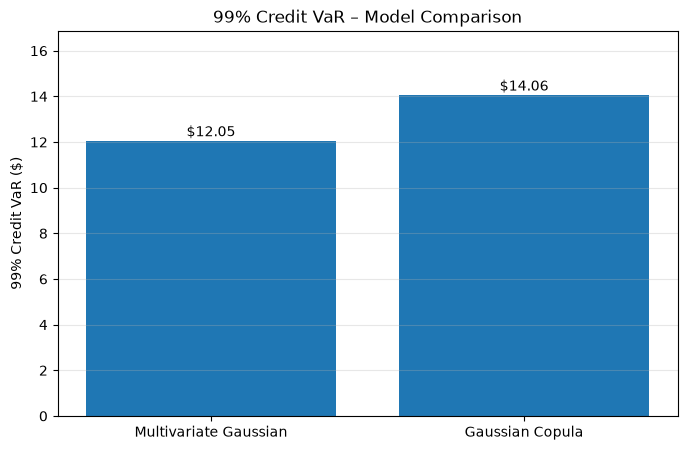

In [13]:
plt.figure(figsize=(8, 5))

plt.bar(comparison["Method"], comparison["99% Credit VaR ($)"])

plt.ylabel("99% Credit VaR ($)")
plt.title("99% Credit VaR – Model Comparison")

plt.grid(axis="y", alpha=0.3)

for i, value in enumerate(comparison["99% Credit VaR ($)"]):
    plt.text(i, value + 0.2, f"${value:.2f}", ha="center")

plt.ylim(0, max(var99_A, var99_B) * 1.2)
plt.show()

### Interpretation

The Gaussian copula produces a higher 99% Credit VaR than the multivariate Gaussian approximation.

The difference comes from the way each model represents future bond values. Method A assumes a continuous normal distribution, while Method B preserves the discrete credit rating transitions, including the large loss associated with default.

As a result, Method B captures the asymmetric nature of credit losses more accurately under the assumed transition table.

The mean net losses are close to zero in both models because the portfolio reference value was defined as the expected future value. The expected positive losses differ because the two models have different loss distributions.

Overall, the results show that the choice of marginal distribution matters when estimating portfolio credit risk, particularly in the tail.

### Why Are the Expected Positive Losses Different?

The mean net loss is approximately zero in both models because gains and losses offset each other.

However, expected positive loss only considers losses, treating gains as zero.

The Gaussian model produces more frequent moderate gains and losses, while the copula model concentrates most outcomes around the BBB rating, with occasional large losses from downgrades or default.

Therefore, the copula can produce a higher 99% VaR but a lower expected positive loss. The two measures describe different aspects of the loss distribution.

## Expected Credit Loss and Reference Value

So far, we have used the expected future bond value as the portfolio reference value, as a result, the expected net loss is approximately zero by construction.

To obtain a more economically meaningful comparison, we also consider the BBB bond value of $107.55 as a benchmark. This allows us to measure the expected gain or loss from credit rating migrations relative to the scenario in which the bond remains BBB.

This is a simplifying assumption, since the actual current market price is not provided.

In [14]:
# BBB benchmark value
bbb_value = bond_values[ratings.index("BBB")]

# Expected net loss relative to BBB
expected_net_loss_bond = bbb_value - mean_value

# Expected downside loss for one bond
expected_downside_bond = np.sum(
    probabilities * np.maximum(bbb_value - bond_values, 0)
)

# Expected default-only loss relative to BBB
expected_default_loss_bond = (
    probabilities[-1] * (bbb_value - bond_values[-1])
)

print(f"BBB benchmark value: ${bbb_value:.4f}")
print(f"Expected future value: ${mean_value:.4f}")
print(f"Expected net migration loss (1 bond): ${expected_net_loss_bond:.4f}")
print(f"Expected downside migration loss (1 bond): ${expected_downside_bond:.4f}")
print(f"Expected default-only loss (1 bond): ${expected_default_loss_bond:.4f}")
print(f"Expected net migration loss (2 bonds): ${2 * expected_net_loss_bond:.4f}")

BBB benchmark value: $107.5500
Expected future value: $107.0879
Expected net migration loss (1 bond): $0.4621
Expected downside migration loss (1 bond): $0.5339
Expected default-only loss (1 bond): $0.1016
Expected net migration loss (2 bonds): $0.9242


### Expected Loss and Correlation

The expected value of a portfolio is the sum of the expected values of its individual bonds, regardless of their correlation.

Changing the correlation does not change the probability of each rating for an individual bond. It only changes how often the bonds experience gains or losses together.

Therefore, both models have the same theoretical expected net loss when measured against the BBB benchmark.

However, correlation affects the probability of large simultaneous losses, which changes the portfolio's VaR. It can also affect the expected positive portfolio loss, since gains and losses may offset each other differently.

## Portfolio Size and Credit Risk

We now extend the analysis to portfolios of 10 and 100 BBB bonds.

We assume that all bonds have the same marginal rating distribution and a pairwise Gaussian correlation parameter of 0.5.

To generate correlated normal variables, we use a common factor model. Each bond is affected by a shared systematic risk factor and an independent individual shock.

We use the same simulated normal variables for both methods. Method A transforms them directly into normally distributed bond values, while Method B uses the Gaussian CDF and the rating transition table.

We compare the 99% Credit VaR as the number of bonds increases.

### Extending the Gaussian Copula to More Bonds

The process is the same as for the two-bond portfolio, but we now simulate 10 or 100 correlated variables instead of two.

We use a common factor model to generate the dependence between bonds. Each bond is affected by the same systematic risk factor and its own independent shock. This produces a correlation of 0.5 between the underlying normal variables.

For the Gaussian copula, we transform these normal variables into uniforms using the normal CDF. We then use the cumulative transition probabilities to assign a future credit rating and value to each bond.

For every simulation, we add the values of all bonds to obtain the future portfolio value and calculate the corresponding loss.

We repeat this process 1,000,000 times for each portfolio size and estimate the 99% Credit VaR.

In [15]:
def simulate_portfolio_var(n_bonds):

    losses_A_n = np.empty(N)
    losses_B_n = np.empty(N)

    reference_value = n_bonds * mean_value
    chunk_size = 50_000

    for start in range(0, N, chunk_size):

        end = min(start + chunk_size, N)
        m = end - start

        # Common factor and independent shocks
        factor = rng.standard_normal((m, 1))
        shocks = rng.standard_normal((m, n_bonds))

        Z = np.sqrt(rho) * factor + np.sqrt(1 - rho) * shocks

        # Method A: Multivariate Gaussian
        portfolio_A = n_bonds * mean_value + std_value * Z.sum(axis=1)

        # Method B: Gaussian copula
        U = norm.cdf(Z)
        rating_idx = np.searchsorted(cum_prob, U)
        portfolio_B = values_B[rating_idx].sum(axis=1)

        # Portfolio losses
        losses_A_n[start:end] = reference_value - portfolio_A
        losses_B_n[start:end] = reference_value - portfolio_B

    return (
        np.percentile(losses_A_n, 99),
        np.percentile(losses_B_n, 99)
    )

In [16]:
results = [
    [2, var99_A, var99_B]
]

for n_bonds in [10, 100]:

    var_A, var_B = simulate_portfolio_var(n_bonds)

    results.append([n_bonds, var_A, var_B])

portfolio_results = pd.DataFrame(
    results,
    columns=[
        "Number of Bonds",
        "Gaussian VaR 99% ($)",
        "Copula VaR 99% ($)"
    ]
)

portfolio_results.round(2)

,Number of Bonds,Gaussian VaR 99% ($),Copula VaR 99% ($)
0,2,12.05,14.06
1,10,51.70,73.92
2,100,493.60,581.64


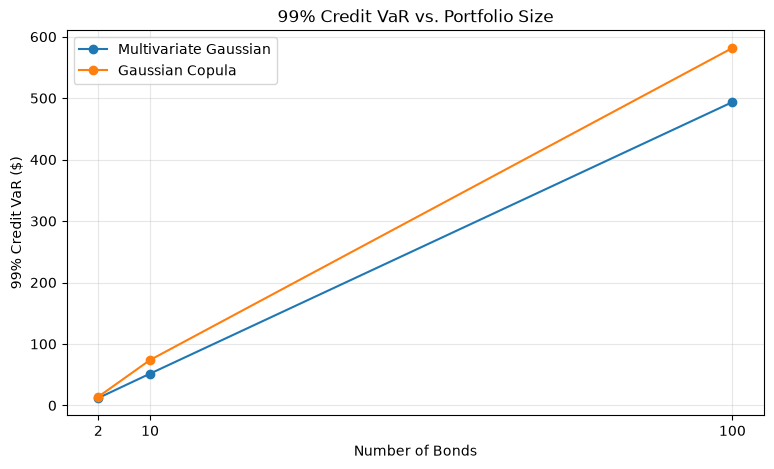

In [17]:
plt.figure(figsize=(9, 5))

plt.plot(
    portfolio_results["Number of Bonds"],
    portfolio_results["Gaussian VaR 99% ($)"],
    marker="o",
    label="Multivariate Gaussian"
)

plt.plot(
    portfolio_results["Number of Bonds"],
    portfolio_results["Copula VaR 99% ($)"],
    marker="o",
    label="Gaussian Copula"
)

plt.xlabel("Number of Bonds")
plt.ylabel("99% Credit VaR ($)")
plt.title("99% Credit VaR vs. Portfolio Size")

plt.xticks([2, 10, 100])
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [18]:
# Expected net loss using BBB as benchmark
portfolio_results["Expected Net Loss vs BBB ($)"] = (
    portfolio_results["Number of Bonds"] * expected_net_loss_bond
)

# 99% VaR using the BBB benchmark instead of the expected future value
portfolio_results["Gaussian VaR vs BBB ($)"] = (
    portfolio_results["Gaussian VaR 99% ($)"]
    + portfolio_results["Expected Net Loss vs BBB ($)"]
)

portfolio_results["Copula VaR vs BBB ($)"] = (
    portfolio_results["Copula VaR 99% ($)"]
    + portfolio_results["Expected Net Loss vs BBB ($)"]
)

portfolio_results.round(2)

,Number of Bonds,Gaussian VaR 99% ($),Copula VaR 99% ($),Expected Net Loss vs BBB ($),Gaussian VaR vs BBB ($),Copula VaR vs BBB ($)
0,2,12.05,14.06,0.92,12.98,14.98
1,10,51.70,73.92,4.62,56.33,78.54
2,100,493.60,581.64,46.21,539.81,627.85


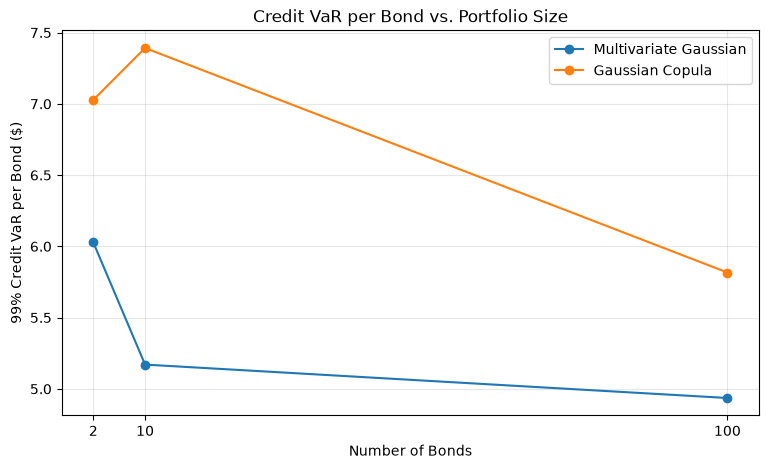

In [19]:
portfolio_results["Gaussian VaR per Bond ($)"] = (
    portfolio_results["Gaussian VaR 99% ($)"]
    / portfolio_results["Number of Bonds"]
)

portfolio_results["Copula VaR per Bond ($)"] = (
    portfolio_results["Copula VaR 99% ($)"]
    / portfolio_results["Number of Bonds"]
)

plt.figure(figsize=(9, 5))

plt.plot(
    portfolio_results["Number of Bonds"],
    portfolio_results["Gaussian VaR per Bond ($)"],
    marker="o",
    label="Multivariate Gaussian"
)

plt.plot(
    portfolio_results["Number of Bonds"],
    portfolio_results["Copula VaR per Bond ($)"],
    marker="o",
    label="Gaussian Copula"
)

plt.xlabel("Number of Bonds")
plt.ylabel("99% Credit VaR per Bond ($)")
plt.title("Credit VaR per Bond vs. Portfolio Size")

plt.xticks([2, 10, 100])
plt.grid(alpha=0.3)
plt.legend()
plt.show()


### Results – Portfolio Size

As the number of bonds increases from 2 to 100, the total 99% Credit VaR increases under both methods. This is expected because we are adding more bonds to the portfolio, so the total exposure becomes larger. For example, under the Gaussian copula, VaR increases from $14.06 for 2 bonds to $581.64 for 100 bonds.

The Gaussian copula produces a higher VaR than the multivariate Gaussian model in all three cases. The main difference is how we model the individual bond values. The Gaussian model approximates them with a continuous normal distribution, while the copula model keeps the original rating probabilities and bond values, including the large loss associated with default. This makes the loss distribution asymmetric and allows for more severe outcomes.

However, increasing the total VaR does not necessarily mean that the portfolio becomes riskier per bond. To understand the effect of diversification, we divide the VaR by the number of bonds.

Under the Gaussian model, VaR per bond decreases from $6.03 to $4.94 as the portfolio grows. This happens because the individual shocks partly offset each other when more bonds are included.

Under the copula model, VaR per bond initially increases from $7.03 to $7.39 for 10 bonds, before decreasing to $5.82 for 100 bonds. Unlike the Gaussian model, the copula produces a discrete loss distribution, where certain combinations of downgrades and defaults can cause large jumps in portfolio losses. As a result, the 99th percentile does not necessarily decrease smoothly when measured per bond.

Finally, diversification cannot eliminate all the credit risk because we assumed a positive correlation parameter of 0.5. All bonds are exposed to the same systematic risk factor, meaning that adverse credit events can affect several issuers at the same time. Adding more bonds reduces the impact of individual shocks, but the common risk remains.


## Conclusion

The Gaussian copula gives a higher 99% Credit VaR than the multivariate Gaussian approximation for portfolios of 2, 10 and 100 bonds. Both models use a Gaussian dependence parameter of 0.5, but they treat individual bond values differently: Method A uses a normal approximation, while Method B keeps the rating transition table, including the large loss in default.

The expected future bond value is the same in both models because we use the same marginal probabilities and values. The dependence structure affects how frequently several bonds experience bad outcomes together, which matters for the tail of the portfolio loss distribution.

Total VaR rises as more bonds are added because total exposure increases. Looking at VaR per bond shows some diversification benefit, although the common risk factor prevents the risk from disappearing completely.